# Employee Attrition Analysis with Python

This project analyzes employee attrition using Python and pandas.

The goal is to identify key factors that may be associated with employee turnover and provide practical recommendations for HR decision-making.

Main areas explored:
- Overall attrition rate
- Department and job role differences
- Overtime
- Monthly income
- Job satisfaction
- Work-life balance
- Employee age and tenure
- Business travel

Tools used:
- Python
- pandas
- matplotlib
- Google Colab

In [ ]:
import pandas as pd

df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [ ]:
# What does the dataset look like?

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
# How many rows and columns are in the dataset?

df.shape

(1470, 35)

In [ ]:
# What are the column names in the dataset?

df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='object')

In [ ]:
# What data types does each column have?

df.dtypes

,0
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64


In [ ]:
# Are there any missing values in the dataset?

df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [ ]:
# What is the overall employee attrition rate?

df["Attrition"].value_counts(normalize=True) * 100

,proportion
Attrition,
No,83.877551
Yes,16.122449


In [ ]:
# Which department has the highest attrition rate?

df.groupby("Department")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Attrition
Department,
Sales,20.627803
Human Resources,19.047619
Research & Development,13.839750


In [ ]:
# Does overtime relate to employee attrition?

df.groupby("OverTime")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
)

,Attrition
OverTime,
No,10.436433
Yes,30.528846


In [ ]:
# Do employees who leave have lower monthly income?

df.groupby("Attrition")["MonthlyIncome"].mean()

,MonthlyIncome
Attrition,
No,6832.739659
Yes,4787.092827


In [ ]:
# Which job roles have the highest attrition rates?

df.groupby("JobRole")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Attrition
JobRole,
Sales Representative,39.759036
Laboratory Technician,23.938224
Human Resources,23.076923
Sales Executive,17.484663
Research Scientist,16.095890
Manufacturing Director,6.896552
Healthcare Representative,6.870229
Manager,4.901961
Research Director,2.500000


In [ ]:
# Does job satisfaction relate to employee attrition?

df.groupby("JobSatisfaction")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
)

,Attrition
JobSatisfaction,
1,22.837370
2,16.428571
3,16.515837
4,11.328976


In [ ]:
# Does distance from home relate to employee attrition?

df.groupby("Attrition")["DistanceFromHome"].mean()

,DistanceFromHome
Attrition,
No,8.915653
Yes,10.632911


In [ ]:
# Do employees who leave tend to be younger?

df.groupby("Attrition")["Age"].mean()

,Age
Attrition,
No,37.561233
Yes,33.607595


In [ ]:
# Do employees who leave have shorter tenure at the company?

df.groupby("Attrition")["YearsAtCompany"].mean()

,YearsAtCompany
Attrition,
No,7.369019
Yes,5.130802


In [ ]:
# Does business travel relate to employee attrition?

df.groupby("BusinessTravel")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

,Attrition
BusinessTravel,
Travel_Frequently,24.909747
Travel_Rarely,14.956855
Non-Travel,8.000000


In [ ]:
# Does work-life balance relate to employee attrition?

df.groupby("WorkLifeBalance")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
)

,Attrition
WorkLifeBalance,
1,31.250000
2,16.860465
3,14.221725
4,17.647059


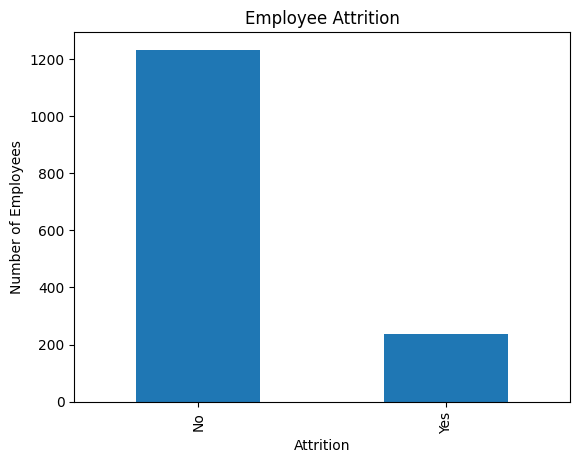

In [ ]:
# How many employees stayed and left the company?

import matplotlib.pyplot as plt

df["Attrition"].value_counts().plot(kind="bar")

plt.title("Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")
plt.show()

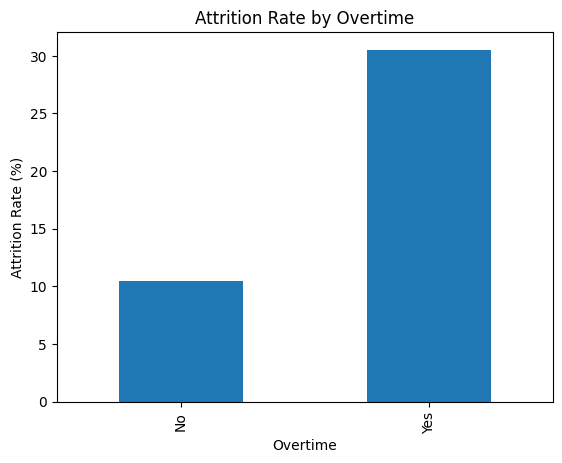

In [ ]:
# How does overtime affect employee attrition?

overtime_attrition = df.groupby("OverTime")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
)

overtime_attrition.plot(kind="bar")

plt.title("Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")
plt.show()

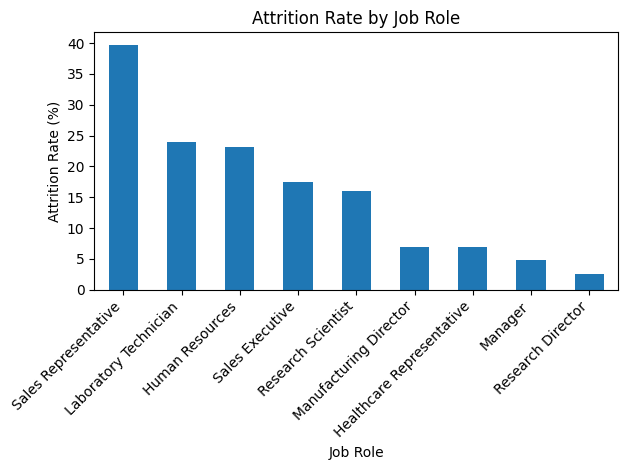

In [ ]:
# Which job roles have the highest attrition rates?

jobrole_attrition = df.groupby("JobRole")["Attrition"].apply(
    lambda x: (x == "Yes").mean() * 100
).sort_values(ascending=False)

jobrole_attrition.plot(kind="bar")

plt.title("Attrition Rate by Job Role")
plt.xlabel("Job Role")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

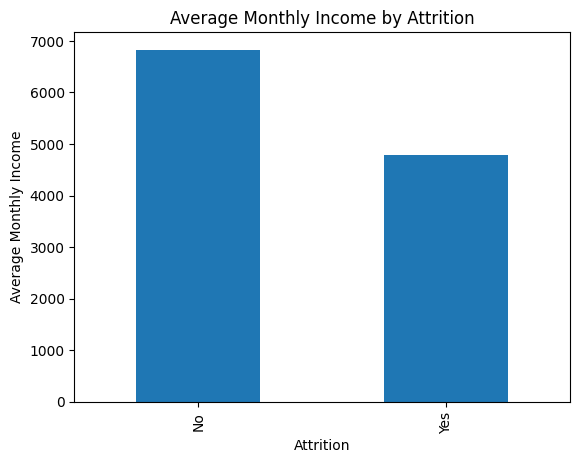

In [ ]:
# How does monthly income differ between employees who stayed and left?

df.groupby("Attrition")["MonthlyIncome"].mean().plot(kind="bar")

plt.title("Average Monthly Income by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Average Monthly Income")
plt.show()

## Key Business Insights

1. Overtime appears to be strongly associated with employee attrition. Employees who work overtime have an attrition rate of about 30.5%, compared with about 10.4% for employees who do not work overtime.

2. Sales Representative has the highest attrition rate at about 39.8%, followed by Laboratory Technician at about 23.9%.

3. Employees who leave have a lower average monthly income (about 4,787) compared with employees who stay (about 6,833).

4. Shorter tenure and younger age may also be associated with higher attrition, indicating that newer and younger employees could require more retention support.

5. Work-life balance, business travel, and job satisfaction are also associated with differences in attrition rates and should be considered together rather than individually.

## Business Recommendations

1. Review overtime policies and workload distribution, especially for teams with high attrition.

2. Develop targeted retention strategies for job roles with higher attrition rates.

3. Review compensation levels for employees in higher-risk groups.

4. Provide stronger onboarding and career development support for newer employees.

5. Regularly monitor employee satisfaction and work-life balance to identify potential retention risks early.